In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import hilbert 
from scipy.special import erfc
rng= np.random.default_rng(42)
fs=1000
t=np.linspace(0,1,fs)
fc=50
fm=5
message= np.sin(2* np.pi * fm *t)

In [2]:
def am_transmit(msg):
    carrier= np.sin(2* np.pi * fc*t)
    return (1+msg) * carrier

def am_receive(rx):
    envelope= np.abs(hilbert(rx))
    return envelope - np.mean(envelope)

EXPERIMENT 1: Noise sweep on the analog AM chain
  noise std =  0.05  ->  SNR =  24.77 dB
  noise std =  0.30  ->  SNR =   9.20 dB
  noise std =  1.00  ->  SNR =  -1.25 dB


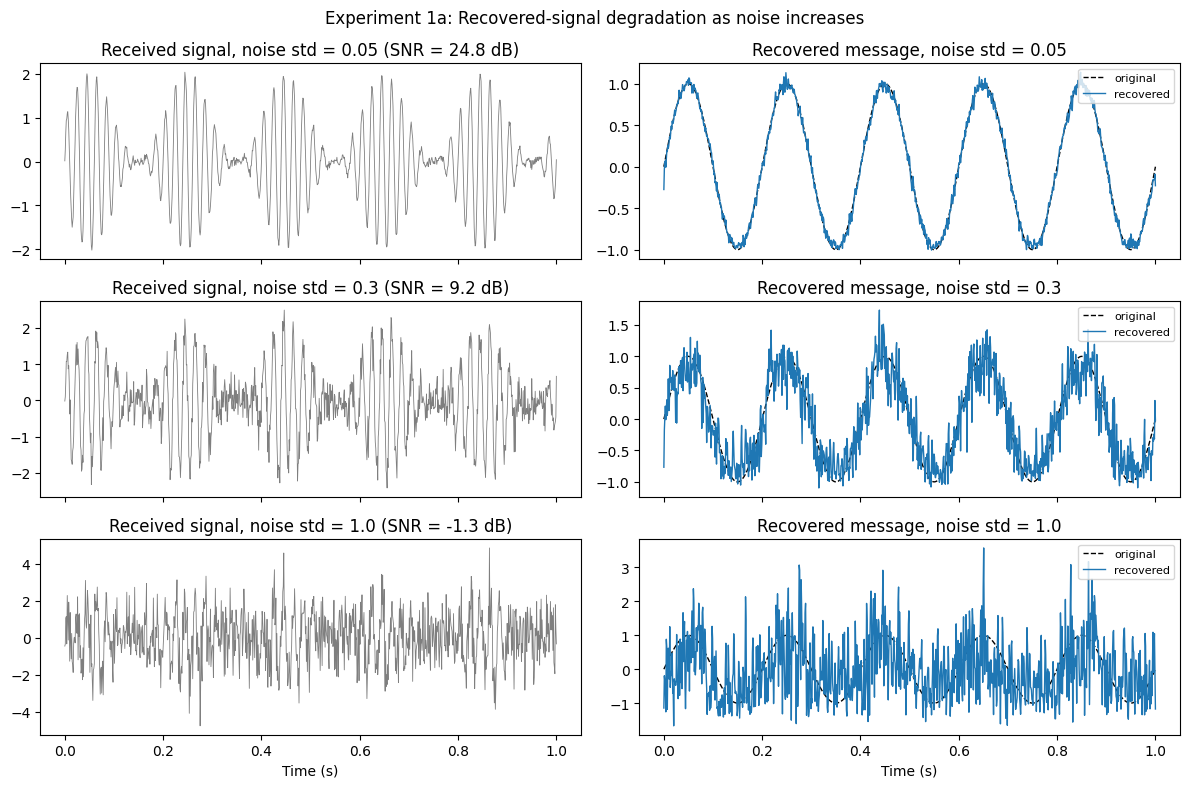

In [3]:
print("=" * 60)
print("EXPERIMENT 1: Noise sweep on the analog AM chain")
print("=" * 60)

tx_signal =am_transmit(message)
signal_power = np.mean(tx_signal ** 2)

noise_levels_demo = [0.05, 0.3, 1.0]

fig, axes = plt.subplots(len(noise_levels_demo), 2, figsize=(12, 8), sharex=True)
for row, sigma in enumerate(noise_levels_demo):
    noise = rng.normal(0, sigma, len(t))
    rx_signal = tx_signal + noise
    recovered = am_receive(rx_signal)

    snr_db = 10 * np.log10(signal_power / sigma**2)
    print(f"  noise std = {sigma:>5.2f}  ->  SNR = {snr_db:6.2f} dB")

    axes[row, 0].plot(t, rx_signal, lw=0.6, color="tab:gray")
    axes[row, 0].set_title(f"Received signal, noise std = {sigma} (SNR = {snr_db:.1f} dB)")
    axes[row, 1].plot(t, message, "k--", lw=1, label="original")
    axes[row, 1].plot(t, recovered, color="tab:blue", lw=1, label="recovered")
    axes[row, 1].set_title(f"Recovered message, noise std = {sigma}")
    axes[row, 1].legend(loc="upper right", fontsize=8)

axes[-1, 0].set_xlabel("Time (s)")
axes[-1, 1].set_xlabel("Time (s)")
fig.suptitle("Experiment 1a: Recovered-signal degradation as noise increases")
fig.tight_layout()
fig.savefig("exp1_noise_sweep_waveforms.png", dpi=150)

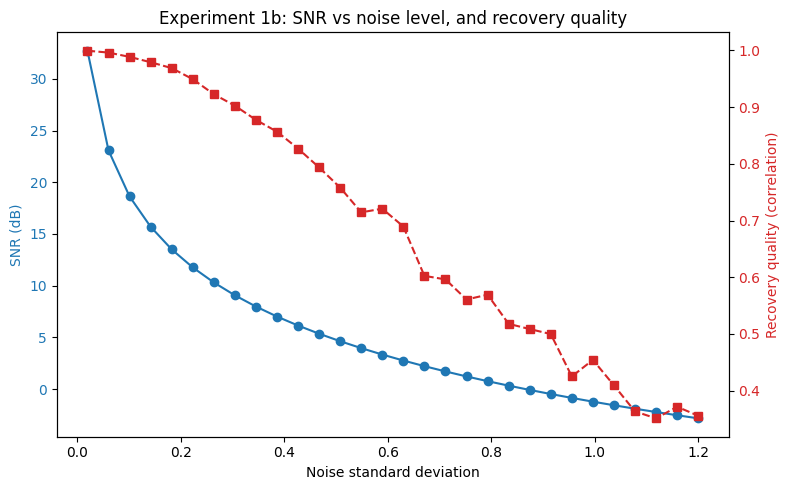

In [4]:
noise_sweep = np.linspace(0.02, 1.2, 30)
snr_sweep_db = 10 * np.log10(signal_power / noise_sweep**2)

quality = []
for sigma in noise_sweep:
    rx = tx_signal + rng.normal(0, sigma, len(t))
    rec = am_receive(rx)
    quality.append(np.corrcoef(message, rec)[0, 1])

fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(noise_sweep, snr_sweep_db, "o-", color="tab:blue", label="SNR (dB)")
ax1.set_xlabel("Noise standard deviation")
ax1.set_ylabel("SNR (dB)", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")
ax2 = ax1.twinx()
ax2.plot(noise_sweep, quality, "s--", color="tab:red",
         label="Correlation (recovered vs original)")
ax2.set_ylabel("Recovery quality (correlation)", color="tab:red")
ax2.tick_params(axis="y", labelcolor="tab:red")
plt.title("Experiment 1b: SNR vs noise level, and recovery quality")
fig.tight_layout()
fig.savefig("exp1_snr_vs_noise.png", dpi=150)



EXPERIMENT 2: Modulation-scheme comparison
  AM recovery correlation at noise std 0.5: 0.781
  FM recovery correlation at noise std 0.5: 0.850


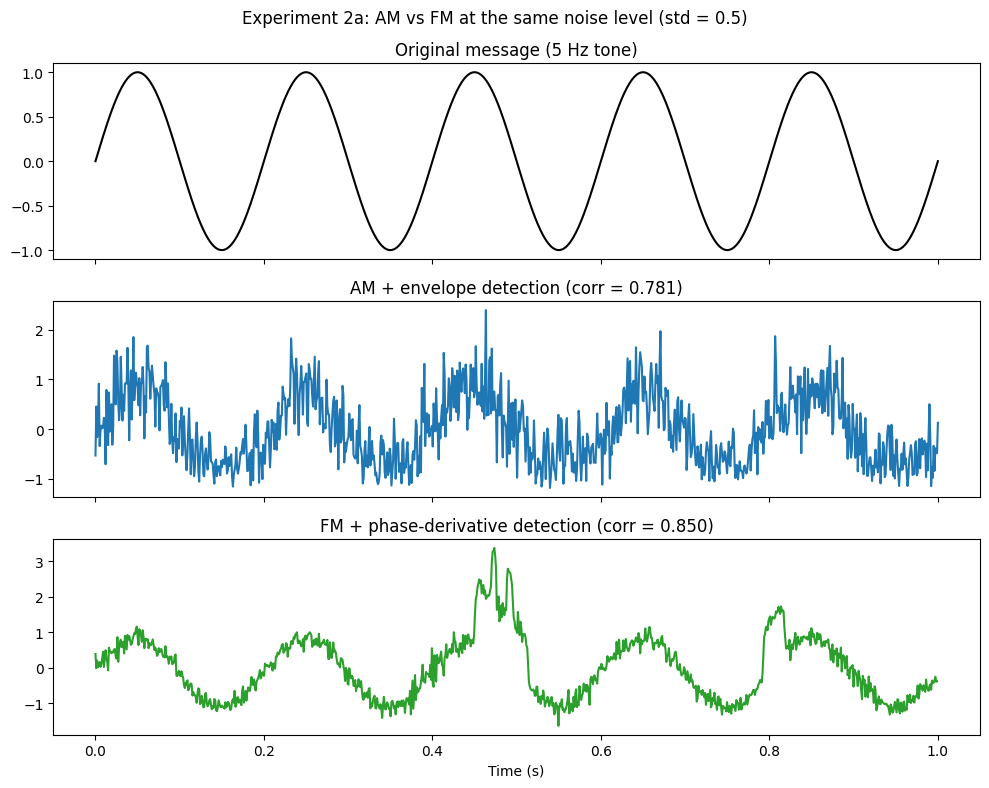

In [ ]:
print("\n" + "=" * 60)
print("EXPERIMENT 2: Modulation-scheme comparison")
print("=" * 60)

sigma_analog = 0.5 
kf = 30.0
phase = 2 * np.pi * fc * t + 2 * np.pi * kf * np.cumsum(message) / fs
fm_tx = np.cos(phase)
noise = rng.normal(0, sigma_analog, len(t))
am_rx = am_transmit(message) + noise
fm_rx = fm_tx + noise

am_rec = am_receive(am_rx)

analytic = hilbert(fm_rx)
inst_phase = np.unwrap(np.angle(analytic))
inst_freq = np.diff(inst_phase) * fs / (2 * np.pi)
fm_rec = (inst_freq - fc) / kf 
fm_rec = fm_rec - np.mean(fm_rec)
win = 25
fm_rec_smooth = np.convolve(fm_rec, np.ones(win) / win, mode="same")
am_corr = np.corrcoef(message, am_rec)[0, 1]
fm_corr = np.corrcoef(message[:-1], fm_rec_smooth)[0, 1]
print(f"  AM recovery correlation at noise std {sigma_analog}: {am_corr:.3f}")
print(f"  FM recovery correlation at noise std {sigma_analog}: {fm_corr:.3f}")
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
axes[0].plot(t, message, "k")
axes[0].set_title("Original message (5 Hz tone)")
axes[1].plot(t, am_rec, color="tab:blue")
axes[1].set_title(f"AM + envelope detection (corr = {am_corr:.3f})")
axes[2].plot(t[:-1], fm_rec_smooth, color="tab:green")
axes[2].set_title(f"FM + phase-derivative detection (corr = {fm_corr:.3f})")
axes[2].set_xlabel("Time (s)")
fig.suptitle(f"Experiment 2a: AM vs FM at the same noise level (std = {sigma_analog})")
fig.tight_layout() 
fig.savefig("exp2_am_vs_fm.png", dpi=150)

  At 8 dB: ASK BER = 6.05e-03,  PSK BER = 2.10e-04
  -> PSK is more robust: its two states are +1/-1 (maximum separation),
while ASK 'wastes' half the decision distance by turning one state off.


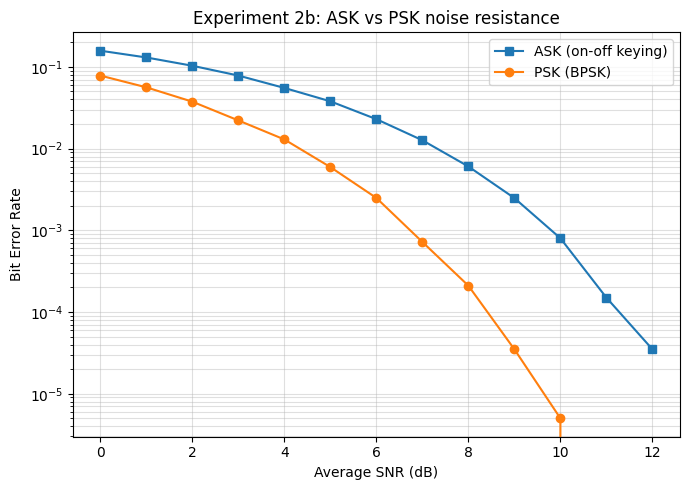

In [6]:
def digital_ber(num_bits, snr_db, scheme):
    bits = rng.integers(0, 2, num_bits)

    if scheme == "PSK":
        symbols = 2 * bits - 1.0
        avg_energy = 1.0
        threshold = 0.0
    elif scheme == "ASK":
        amp = np.sqrt(2.0)
        symbols = bits * amp
        avg_energy = 1.0
        threshold = amp / 2
    else:
        raise ValueError(scheme)

    snr_linear = 10 ** (snr_db / 10)
    noise_std = np.sqrt(avg_energy / (2 * snr_linear))
    received = symbols + rng.normal(0, noise_std, num_bits)
    detected = (received > threshold).astype(int)
    return np.mean(detected != bits)
num_bits_cmp = 200_000
snr_range_db = np.arange(0, 13, 1)
ber_ask = [digital_ber(num_bits_cmp, s, "ASK") for s in snr_range_db]
ber_psk = [digital_ber(num_bits_cmp, s, "PSK") for s in snr_range_db]
plt.figure(figsize=(7, 5))
plt.semilogy(snr_range_db, ber_ask, "s-", label="ASK (on-off keying)")
plt.semilogy(snr_range_db, ber_psk, "o-", label="PSK (BPSK)")
plt.xlabel("Average SNR (dB)")
plt.ylabel("Bit Error Rate")
plt.title("Experiment 2b: ASK vs PSK noise resistance")
plt.grid(True, which="both", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.savefig("exp2_ask_vs_psk.png", dpi=150)
print(f"  At 8 dB: ASK BER = {ber_ask[8]:.2e},  PSK BER = {ber_psk[8]:.2e}")
print("  -> PSK is more robust: its two states are +1/-1 (maximum separation),")
print("while ASK 'wastes' half the decision distance by turning one state off.")


EXPERIMENT 3: BER vs SNR (1,000,000 bits) with QPSK extension
  SNR  4 dB:  BPSK BER = 1.27e-02   QPSK BER = 5.68e-02
  SNR  8 dB:  BPSK BER = 1.78e-04   QPSK BER = 5.96e-03
  SNR 12 dB:  BPSK BER = 0.00e+00   QPSK BER = 3.40e-05
QPSK carries 2 bits/symbol (double the data rate) but needs ~3 dB
more symbol SNR for the same BER: the classic rate-vs-reliability tradeoff.


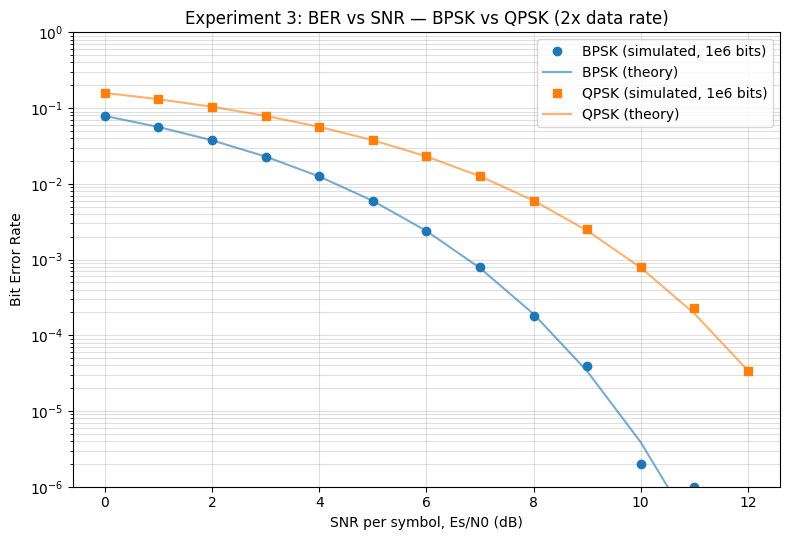

In [7]:
print("\n" + "=" * 60)
print("EXPERIMENT 3: BER vs SNR (1,000,000 bits) with QPSK extension")
print("=" * 60)

def bpsk_ber(num_bits, snr_db):
    bits = rng.integers(0, 2, num_bits)
    symbols = 2 * bits - 1.0
    snr_linear = 10 ** (snr_db / 10)
    noise = rng.normal(0, np.sqrt(1 / (2 * snr_linear)), num_bits)
    detected = (symbols + noise > 0).astype(int)
    return np.mean(detected != bits)


def qpsk_ber(num_bits, snr_db):
    num_bits -= num_bits % 2
    bits = rng.integers(0, 2, num_bits)
    i_bits, q_bits = bits[0::2], bits[1::2]
    i_sym = (2 * i_bits - 1) / np.sqrt(2)
    q_sym = (2 * q_bits - 1) / np.sqrt(2)

    snr_linear = 10 ** (snr_db / 10)
    noise_std = np.sqrt(1 / (2 * snr_linear))
    i_rx = i_sym + rng.normal(0, noise_std, len(i_sym))
    q_rx = q_sym + rng.normal(0, noise_std, len(q_sym))

    det = np.empty(num_bits, dtype=int)
    det[0::2] = (i_rx > 0).astype(int)
    det[1::2] = (q_rx > 0).astype(int)
    return np.mean(det != bits)
num_bits_big = 1_000_000
snr_range_db = np.arange(0, 13, 1)
snr_linear = 10 ** (snr_range_db / 10)

ber_bpsk = [bpsk_ber(num_bits_big, s) for s in snr_range_db]
ber_qpsk = [qpsk_ber(num_bits_big, s) for s in snr_range_db]
theory_bpsk = 0.5 * erfc(np.sqrt(snr_linear))
theory_qpsk = 0.5 * erfc(np.sqrt(snr_linear / 2))

plt.figure(figsize=(8, 5.5))
plt.semilogy(snr_range_db, ber_bpsk, "o", color="tab:blue", label="BPSK (simulated, 1e6 bits)")
plt.semilogy(snr_range_db, theory_bpsk, "-", color="tab:blue", alpha=0.6, label="BPSK (theory)")
plt.semilogy(snr_range_db, ber_qpsk, "s", color="tab:orange", label="QPSK (simulated, 1e6 bits)")
plt.semilogy(snr_range_db, theory_qpsk, "-", color="tab:orange", alpha=0.6, label="QPSK (theory)")
plt.xlabel("SNR per symbol, Es/N0 (dB)")
plt.ylabel("Bit Error Rate")
plt.title("Experiment 3: BER vs SNR — BPSK vs QPSK (2x data rate)")
plt.grid(True, which="both", alpha=0.4)
plt.ylim(1e-6, 1)
plt.legend()
plt.tight_layout()
plt.savefig("exp3_ber_bpsk_qpsk.png", dpi=150)

for s in (4, 8, 12):
    idx = int(np.where(snr_range_db == s)[0][0])
    print(f"  SNR {s:2d} dB:  BPSK BER = {ber_bpsk[idx]:.2e}   QPSK BER = {ber_qpsk[idx]:.2e}")
print("QPSK carries 2 bits/symbol (double the data rate) but needs ~3 dB")
print("more symbol SNR for the same BER: the classic rate-vs-reliability tradeoff.")

plt.show()